# 신경망의 순전파·미분·갱신

작은 예제로 원리 확인 → 코드 실행 → 한 조건 변경 → 결과 해석

위에서 아래로 실행. 일반 CPU로 진행 가능. 날짜·평가 운영은 학기 운영안내에서 확인

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=5, suppress=True)

## 순전파

두 ReLU 경로를 더한 신경망이다. x=0·0.5·1에서 각 경로의 중간값과 출력을 구하시오.

In [2]:
x=np.array([0.,.5,1.]);y=np.array([0.,1.,0.])
p=np.array([1.43,-.61,-3.89,2.63,-.27,1.35]) # W1,B1,W3,W2,B2,W4
def forward(p,x):
    w1,b1,w3,w2,b2,w4=p
    h1=np.maximum(w1*x+b1,0);h2=np.maximum(w2*x+b2,0)
    return w3*h1+w4*h2
h1=np.maximum(p[0]*x+p[1],0);h2=np.maximum(p[3]*x+p[4],0)
display(pd.DataFrame({'x':x,'h1':h1,'h2':h2,'yhat':forward(p,x),'y':y}))
assert np.allclose(forward(p,x),[0.,1.0023,-.0038])

,x,h1,h2,yhat,y
0,0.0,0.000,0.000,0.0000,0.0
1,0.5,0.105,1.045,1.0023,1.0
2,1.0,0.820,2.360,-0.0038,0.0


## 역전파와 수치미분

SSR=Σ(yhat−y)²의 여섯 미분값을 구하시오. 직접 구현·자동미분·중앙차분 결과를 비교하시오. ReLU 미분 조건은 활성화 전 값 z>0. z=0에서는 계산 규약으로 0 사용.

In [3]:
import torch
torch.set_num_threads(1)
def gradient(p,x,y):
    w1,b1,w3,w2,b2,w4=p
    z1=w1*x+b1;z2=w2*x+b2
    h1=np.maximum(z1,0);h2=np.maximum(z2,0)
    e=w3*h1+w4*h2-y
    return 2*np.array([sum(e*w3*(z1>0)*x),sum(e*w3*(z1>0)),sum(e*h1),
                       sum(e*w4*(z2>0)*x),sum(e*w4*(z2>0)),sum(e*h2)])
pt=torch.tensor(p,dtype=torch.float64,requires_grad=True)
xt=torch.tensor(x,dtype=torch.float64);yt=torch.tensor(y,dtype=torch.float64)
out=pt[2]*torch.relu(pt[0]*xt+pt[1])+pt[5]*torch.relu(pt[3]*xt+pt[4])
((out-yt)**2).sum().backward()
eps=1e-6;eye=np.eye(6)
loss=lambda a:np.sum((forward(a,x)-y)**2)
finite=np.array([(loss(p+eps*v)-loss(p-eps*v))/(2*eps) for v in eye])
g=gradient(p,x,y)
display(pd.DataFrame({'manual':g,'autograd':pt.grad.numpy(),'central_difference':finite}))
assert np.allclose(g,pt.grad.numpy(),atol=1e-10)
assert np.allclose(g,finite,atol=1e-7)

,manual,autograd,central_difference
0,0.020617,0.020617,0.020617
1,0.011670,0.011670,0.011670
2,-0.005749,-0.005749,-0.005749
3,-0.007155,-0.007155,-0.007155
4,-0.004050,-0.004050,-0.004050
5,-0.013129,-0.013129,-0.013129


## 초기값에서 한 번 갱신

파라미터를 `[0.06,0,−4.11,3.49,0,2.74]`, 학습률을 0.01로 두시오. 첫 갱신값을 구하시오. 반올림은 표시할 때만 적용하시오.

In [4]:
initial=np.array([.06,0.,-4.11,3.49,0.,2.74])
g=gradient(initial,x,y); updated=initial-.01*g
display(pd.DataFrame({'parameter':['W1','B1','W3','W2','B2','W4'],
                      'initial':initial,'gradient':g,'updated':updated}))
assert np.isclose(g[0],-91.6119)
assert np.isclose(updated[0],.976119)
# 비활성 경로 미분 점검: x=0, B1<0, B2=.2
changed=p.copy();changed[4]=.2
print('x=0에서 B1의 미분:',gradient(changed,np.array([0.]),np.array([0.]))[1])
assert gradient(changed,np.array([0.]),np.array([0.]))[1] == 0

,parameter,initial,gradient,updated
0,W1,0.06,-91.61190,0.976119
1,B1,0.00,-106.64628,1.066463
2,W3,-4.11,1.33740,-4.123374
3,W2,3.49,61.07460,2.879254
4,B2,0.00,71.09752,-0.710975
5,W4,2.74,77.79210,1.962079


x=0에서 B1의 미분: 0.0


## 반복 갱신

같은 초기값과 학습률로 500회 갱신하시오. 파라미터·SSR·세 관측점의 예측값을 확인하시오. 세 점에 잘 맞는다는 사실만으로 실제 현상을 설명하는 모형이라고 할 수 있는지 설명하시오.

500회 파라미터: [ 1.42816 -0.60944 -3.88946  2.63117 -0.27416  1.35102]
SSR: 1.5961102210819503e-16 예측: [0. 1. 0.]


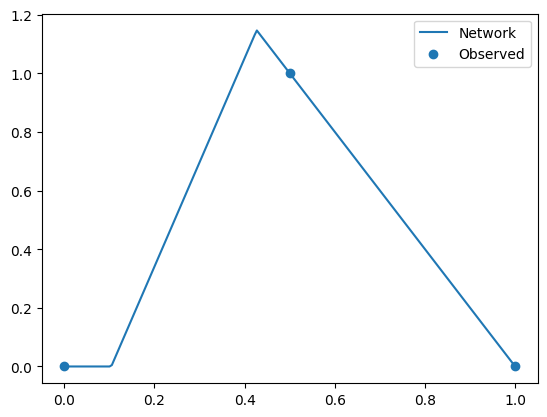

In [5]:
trained=initial.copy();loss_history=[]
for _ in range(500):
    trained-=.01*gradient(trained,x,y)
    loss_history.append(np.sum((forward(trained,x)-y)**2))
print('500회 파라미터:',trained)
print('SSR:',loss_history[-1],'예측:',forward(trained,x))
assert loss_history[-1]<1e-12
grid=np.linspace(0,1,200)
plt.plot(grid,forward(trained,grid),label='Network')
plt.scatter(x,y,label='Observed');plt.legend();plt.show()

## 같은 출력, 다른 파라미터

첫 경로의 입력 가중치·편향을 2배, 출력 가중치를 절반으로 바꾸시오. 출력이 같은지 확인하시오. 음수 배율에서는 같은 관계가 유지되는지 설명하시오.

In [6]:
scaled=p.copy();scaled[:2]*=2;scaled[2]/=2
assert np.allclose(forward(p,x),forward(scaled,x))
print(forward(p,x),forward(scaled,x))

[ 0.      1.0023 -0.0038] [ 0.      1.0023 -0.0038]
